# EDA 01 · Target and dataset overview

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** How many customers churn, and how imbalanced is the target?

**Data.** Raw files converted to parquet in `workshops/data/parquet/`. The target is the labelled March cohort `train_v2` (970,960 users, 9.0 % churn).

**How to read it.** Run the notebooks in order. This first one also converts the raw `.csv.7z` archives to parquet. The closing cell of each notebook lists its conclusions.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

In [ ]:
# Convert the raw .csv.7z archives to parquet once (the schema contract lives in src/data_processing/schemas.py).
sys.path.insert(0, str(W1_DIR.parent))
from w1.src.data_processing.utils import convert_raw_to_parquet

convert_raw_to_parquet(DATA_DIR)

## 1. Target

In [10]:
train_data = pl.read_parquet(PARQUET_DIR / "train_v2.parquet").to_pandas()

In [11]:
train_data.head()

,msno,is_churn
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1


`train_data` contains two columns: `msno` (a long user id) and `is_churn` (our target variable).

In [12]:
train_data.describe()

,is_churn
count,970960.000000
mean,0.089942
std,0.286099
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


Our training dataset contains 970,960 rows with only two possible values (0 and 1). No abrupt value appears in this dataframe.

In [13]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 970960 entries, 0 to 970959
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   msno      970960 non-null  str  
 1   is_churn  970960 non-null  int8 
dtypes: int8(1), str(1)
memory usage: 49.1 MB


There is no null value present in the dataframe. This dataframe takes relatively less memory than the others. Note that binary values are stored as `int64`, which wastes memory; this will be optimized in the data preprocessing step.

### Plotting count vs is_churn to check the balance in the dataset

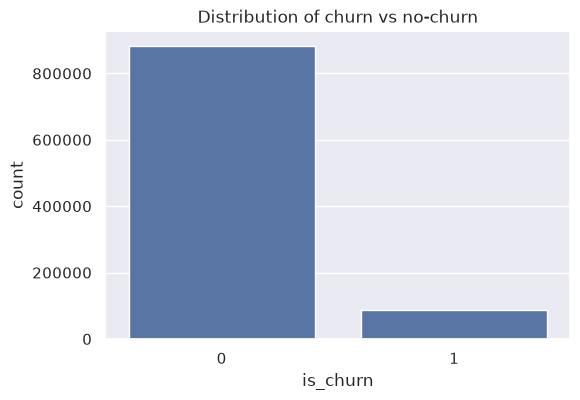

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(x=train_data["is_churn"])
plt.title("Distribution of churn vs no-churn")
plt.xlabel("is_churn")
plt.ylabel("count")
plt.show()

For a business, having few churn users is great, but it makes our dataset imbalanced.

In [15]:
counts = train_data["is_churn"].value_counts()
percents = train_data["is_churn"].value_counts(normalize=True)
no_churn, churn = counts[0], counts[1]

print("Total number of data points in train_v2.csv:", counts.sum())
print("No-churn data points:", no_churn)
print("Churn data points:", churn)
print("No-churn share: {:.3f}%".format(percents[0] * 100))
print("Churn share: {:.3f}%".format(percents[1] * 100))

Total number of data points in train_v2.csv: 970960
No-churn data points: 883630
Churn data points: 87330
No-churn share: 91.006%
Churn share: 8.994%


In [16]:
train_data[train_data["is_churn"].isnull()]

,msno,is_churn


**Target.**

`train_v2` has 970,960 users and no null values. 91% renew and 9% churn, so the dataset is highly imbalanced. That is why we evaluate with log-loss, F1 and the confusion matrix instead of accuracy. `is_churn` fits in `int8`.

---
**Previous:** none (start here) · **Next:** `02_members.ipynb`